# 3. Comparing search methods across 60 drugs

We give six search methods the same **60 simple questions: one for each drug** in the current collection. Each question asks for a section about uses, dosage or warnings.

A match means the method returned a passage from an expected drug label and section. This is a small, automatic section-finding check. **It does not test whether a passage gives a complete or correct medical answer.**

This notebook reads the saved comparison for the active search index and checks that its dataset and search settings still match. Running its cells refreshes the tables and chart without API calls or new retrieval measurements.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.utils.config import digest, load_config, read_json

index_path = ROOT / read_json(ROOT / "results/search_latest.json")["run_path"]
index = read_json(index_path)
comparison = read_json(ROOT / "reports/expanded_60/method_comparison.json")
assert comparison["status"] == "complete", "Finish the comparison before reading its results."
assert comparison["snapshot_id"] == index["snapshot_id"]
assert comparison["index_run_id"] == index["run_id"]
assert comparison["settings"] == index["selection"], "Search settings changed; update the comparison."
assert comparison["source_code_hash"] == digest((ROOT / "src/evaluation/section_check.py").read_text(encoding="utf-8"))
assert load_config()["ingestion"]["lookup_names"] == index["configuration"]["ingestion"]["lookup_names"]
display(
    Markdown(
        f"**{comparison['corpus_drug_names']} drugs | {comparison['corpus_labels']} FDA labels | {comparison['corpus_chunks']:,} searchable passages**\n\n"
        f"Saved comparison completed: {comparison['completed_at']} (UTC)."
    )
)

**60 drugs | 118 FDA labels | 8,601 searchable passages**

Saved comparison completed: 2026-10-20T09:30:29.876306+00:00 (UTC).

## What questions did we ask?

There are 20 questions about uses, 20 about dosage instructions and 20 about warnings. Each drug appears once. These are direct questions about finding a section; they do not include difficult medical reasoning or questions the labels cannot answer.

Before searching, we identified matching labels from their FDA identity fields and checked that the requested section exists. A combination label can list more than one drug. These automatic reference matches have not been independently reviewed for medical relevance.

In [2]:
questions = pd.DataFrame(comparison["questions"])
assert questions["drug"].nunique() == len(questions) == 60
display(questions["topic"].value_counts().rename("Questions").to_frame())
display(
    questions[["drug", "topic", "text"]]
    .head(6)
    .rename(columns={"drug": "Drug", "topic": "Section requested", "text": "Example question"})
)

,Questions
topic,
Uses,20
Dosage,20
Warnings,20


,Drug,Section requested,Example question
0,aspirin,Uses,Find the uses section in a label containing as...
1,metformin,Dosage,Find dosage instructions in a label containing...
2,warfarin,Warnings,Find warnings and precautions in a label conta...
3,lisinopril,Uses,Find the uses section in a label containing li...
4,atorvastatin,Dosage,Find dosage instructions in a label containing...
5,amoxicillin,Warnings,Find warnings and precautions in a label conta...


## What do the methods do?

| Method | Simple explanation |
|---|---|
| Keyword | Looks for matching words |
| BM25 | Matches words, giving more weight to distinctive words |
| Semantic | Looks for similar meaning |
| Hybrid: rank fusion | Combines word and meaning searches using result positions |
| Hybrid: score fusion | Combines word and meaning searches using adjusted scores |
| Hybrid + reranking | Another model reads the question and each candidate passage together to reorder the hybrid results |

All methods search the same saved passages without metadata filters or a score cutoff. The saved settings were reused without tuning on these 60 questions.

The current app uses hybrid retrieval with reranking. It also identifies drug names and question topics, applies metadata filters, removes results below an experimental score cutoff, and can ask an LLM to write a cited answer. Those app steps are outside this comparison.

## How often did they find the requested section?

**Found first** means the first passage came from an expected label and section. **Found in top 10** means at least one of the first ten passages did. For example, 54 out of 60 means 90% of these section-finding questions matched.

Search time is measured after models and question embeddings are ready. It includes ranking and, for hybrid + reranking, the reranking step. It excludes startup, API embedding time, index building and LLM answer writing, so it is not the total time a new user would wait.

In [3]:
method_names = {
    "keyword": "Keyword",
    "bm25": "BM25",
    "dense": "Semantic",
    "hybrid_rrf": "Hybrid: rank fusion",
    "hybrid_normalized": "Hybrid: score fusion",
    "hybrid_rerank": "Hybrid + reranking",
}
results = pd.DataFrame(comparison["methods"]).set_index("method").reindex(method_names)
assert results["questions"].eq(60).all()
table = pd.DataFrame(index=results.index)
for field, title in [("found_first", "Found first"), ("found_in_10", "Found in top 10")]:
    table[title] = results[field].map(lambda count: f"{count}/60 ({count / 60:.0%})")
table["Average search time (ms)"] = results["average_ms"].round(1)
display(table.rename(index=method_names))

,Found first,Found in top 10,Average search time (ms)
method,,,
Keyword,3/60 (5%),7/60 (12%),63.2
BM25,16/60 (27%),41/60 (68%),100.1
Semantic,36/60 (60%),58/60 (97%),6.9
Hybrid: rank fusion,29/60 (48%),56/60 (93%),109.1
Hybrid: score fusion,37/60 (62%),58/60 (97%),101.1
Hybrid + reranking,42/60 (70%),60/60 (100%),4518.5


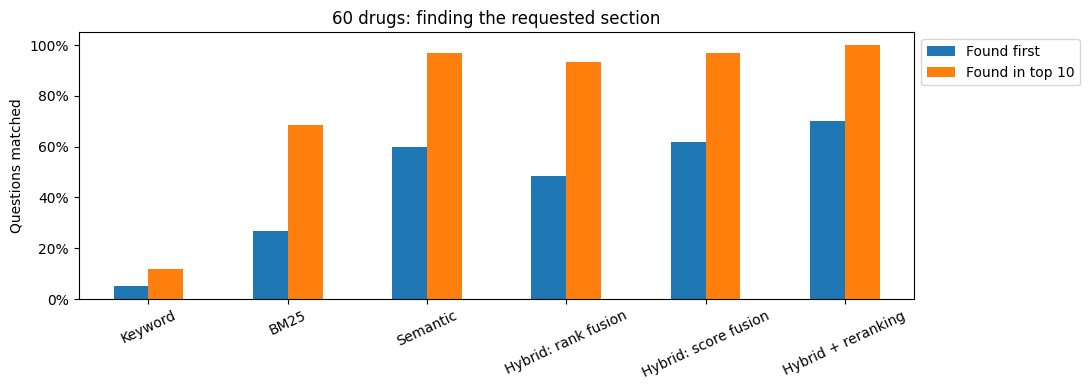

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

scores = results[["found_first", "found_in_10"]].div(results["questions"], axis=0)
scores = scores.rename(
    index=method_names, columns={"found_first": "Found first", "found_in_10": "Found in top 10"}
)
ax = scores.plot.bar(figsize=(11, 4), rot=25)
ax.set(ylabel="Questions matched", xlabel="", ylim=(0, 1.05), title="60 drugs: finding the requested section")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## Look at one drug

Change `drug` below to another name in the collection. The table shows where each method first found a passage from the requested drug label and section. 'Not found' means no match appeared in its first ten passages.

In [5]:
drug = "apixaban"
question = next(question for question in comparison["questions"] if question["drug"] == drug)
display(Markdown("**Question:** " + question["text"]))
details = []
for method in comparison["methods"]:
    row = next(row for row in method["per_question"] if row["drug"] == drug)
    details.append(
        {
            "Method": method_names[method["method"]],
            "First matching position": row["first_matching_rank"] or "Not found",
        }
    )
display(pd.DataFrame(details))

**Question:** Find the uses section in a label containing apixaban.

,Method,First matching position
0,Keyword,Not found
1,BM25,Not found
2,Semantic,Not found
3,Hybrid: rank fusion,Not found
4,Hybrid: score fusion,Not found
5,Hybrid + reranking,1


## What can we conclude?

The table and chart show how well each method located the requested sections across all 60 drugs, and how long that ranking took. Finding the right section is a useful first check, but a passage can still miss a condition, warning or other important detail. Notebook 2 lets you inspect returned source text.

These results describe this simple check, not a final choice of the best method for every question. A broader evaluation needs varied questions, unsupported requests and independent review of the expected evidence.

The current questions, source references and results are saved in `reports/expanded_60/method_comparison.json`. To run or resume the comparison, use `uv run --locked --extra research python scripts/compare_search_methods.py`. This reuses a completed comparison when its index, questions and comparison code still match; otherwise it runs the methods and may use the embedding API.

To refresh only this notebook's tables and chart, use `uv run --locked --extra research python scripts/execute_notebooks.py --notebook 03_retrieval_pipeline_benchmark`.